# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


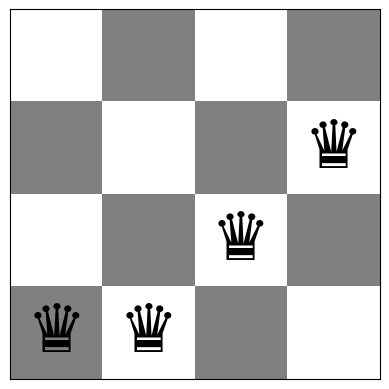

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


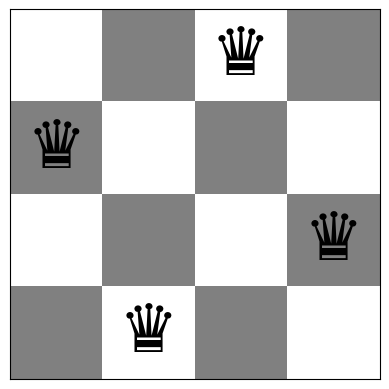

In [4]:
board = [1,3,0,2]
show_board(board)

## Bài 5. Biểu diễn bài toán n quân hậu (khảo sát)

Bên dưới mình khảo sát `random_board`, `conflicts`, `show_board`, bàn cờ mẫu `[1, 3, 0, 2]`, và **kiểm chứng bằng cách đếm trực tiếp từng cặp** (không dùng `conflicts`) rằng $h=0 \iff$ không có cặp quân hậu nào tấn công nhau.

Bàn cờ mẫu: [1, 3, 0, 2] -> h = 0 | các cặp tấn công: []

Bàn cờ ngẫu nhiên n = 4: [1 2 2 0] -> h = 3 | các cặp tấn công: [(0, 1), (1, 2), (1, 3)]
Board with 3 conflicts.


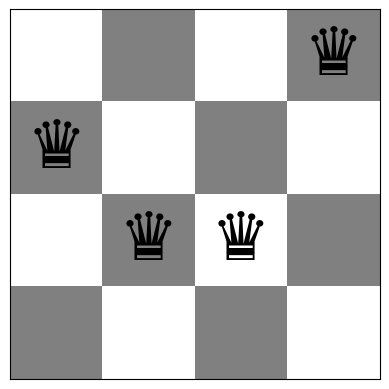


Bàn cờ ngẫu nhiên n = 8: [5 5 5 4 4 3 7 5] -> h = 11 | số cặp tấn công (đếm trực tiếp): 11
Board with 11 conflicts.


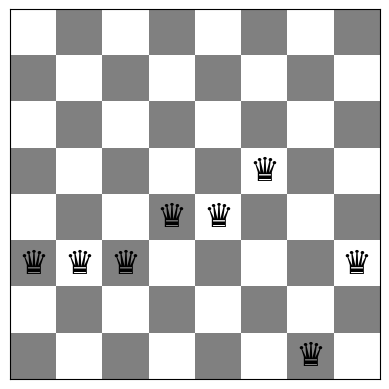

In [5]:
import os, time, math, itertools
import pandas as pd
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)

def attacking_pairs(board):
    """Liệt kê các cặp (i, j), i < j, tấn công nhau. Kiểm tra trực tiếp từng cặp
    (cùng hàng hoặc |chênh lệch hàng| = |chênh lệch cột|), độc lập với conflicts()."""
    n = len(board)
    return [(i, j) for i in range(n) for j in range(i + 1, n)
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i]

def h(board):
    """Hàm mục tiêu h(board) = số cặp quân hậu cùng hàng hoặc cùng đường chéo."""
    return conflicts(board)

# Bàn cờ mẫu hợp lệ [1, 3, 0, 2]
sample = [1, 3, 0, 2]
print("Bàn cờ mẫu:", sample, "-> h =", h(sample), "| các cặp tấn công:", attacking_pairs(sample))

# random_board(n): mỗi cột chọn một hàng ngẫu nhiên (có thể trùng hàng)
np.random.seed(2026)
board4 = random_board(4)
print("\nBàn cờ ngẫu nhiên n = 4:", board4, "-> h =", h(board4), "| các cặp tấn công:", attacking_pairs(board4))
show_board(board4)

board8 = random_board(8)
print("\nBàn cờ ngẫu nhiên n = 8:", board8, "-> h =", h(board8), "| số cặp tấn công (đếm trực tiếp):", len(attacking_pairs(board8)))
show_board(board8, fontsize=24)

### Kiểm chứng $h(\mathbf{q})=0 \iff$ không có cặp quân hậu tấn công nhau

* **n = 4**: duyệt *toàn bộ* $4^4=256$ trạng thái.
* **n = 8**: duyệt toàn bộ $8!=40320$ hoán vị các hàng (mọi nghiệm đều phải là hoán vị, vì hai quân cùng hàng thì đã xung đột), cộng thêm 20 000 bàn cờ ngẫu nhiên (có thể trùng hàng).

Với mỗi bàn cờ ta kiểm tra đồng thời: (a) `conflicts(b)` bằng đúng số cặp tấn công đếm trực tiếp; (b) `conflicts(b) == 0` khi và chỉ khi danh sách cặp tấn công rỗng.

In [6]:
def kiem_tra(boards):
    tong = so_nghiem = sai_lech = 0
    for b in boards:
        p = len(attacking_pairs(b)); c = conflicts(b)
        tong += 1; so_nghiem += (c == 0)
        sai_lech += not (c == p and ((c == 0) == (p == 0)))
    return tong, so_nghiem, sai_lech

np.random.seed(5)
rows = []
t, s, e = kiem_tra(itertools.product(range(4), repeat=4))
rows.append({'n': 4, 'tập kiểm tra': 'toàn bộ 4^4 trạng thái', 'số bàn cờ': t, 'số bàn cờ có h = 0': s, 'số trường hợp sai lệch': e})
t, s, e = kiem_tra(itertools.permutations(range(8)))
rows.append({'n': 8, 'tập kiểm tra': 'toàn bộ 8! hoán vị', 'số bàn cờ': t, 'số bàn cờ có h = 0': s, 'số trường hợp sai lệch': e})
t, s, e = kiem_tra(random_board(8) for _ in range(20000))
rows.append({'n': 8, 'tập kiểm tra': '20 000 bàn cờ ngẫu nhiên', 'số bàn cờ': t, 'số bàn cờ có h = 0': s, 'số trường hợp sai lệch': e})
pd.DataFrame(rows)

,n,tập kiểm tra,số bàn cờ,số bàn cờ có h = 0,số trường hợp sai lệch
0,4,toàn bộ 4^4 trạng thái,256,2,0
1,8,toàn bộ 8! hoán vị,40320,92,0
2,8,20 000 bàn cờ ngẫu nhiên,20000,0,0


# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Cài đặt

**Ý tưởng.** Một *nước đi cục bộ* là chuyển một quân hậu sang hàng khác trong cùng cột, nên mỗi trạng thái có $n(n-1)$ láng giềng. Ở mỗi vòng lặp thuật toán:

1. Tính $h$ của **toàn bộ** $n(n-1)$ láng giềng (mỗi lần gọi `conflicts` tốn $O(n)$).
2. Chọn láng giềng có $h$ nhỏ nhất; nếu có nhiều láng giềng cùng giá trị tốt nhất thì chọn ngẫu nhiên một trong số đó (phá hòa ngẫu nhiên, tránh thiên lệch theo thứ tự duyệt).
3. Chỉ di chuyển nếu $h_{\text{mới}} < h_{\text{hiện tại}}$ (cải thiện **chặt**). Nếu không có láng giềng nào tốt hơn thì dừng: đã đến cực trị cục bộ (hoặc plateau, vì nước đi ngang bằng $h$ không được chấp nhận).

Điều kiện dừng: $h=0$, hoặc không còn nước cải thiện. `max_steps` chỉ là chốt an toàn.

Mỗi thuật toán trả về một dict gồm: bàn cờ cuối, `h` cuối, `steps` (số nước đi đã thực hiện), `evals` (số lần gọi hàm mục tiêu, tính cả lần tính $h$ ban đầu), `iters` (số vòng lặp), `history` (giá trị $h$ sau mỗi vòng lặp) và `moves_h` (giá trị $h$ sau mỗi nước đi được chấp nhận).

Bàn cờ ban đầu: [1 7 0 3 1 7 5 4] | h = 4
Board with 4 conflicts.


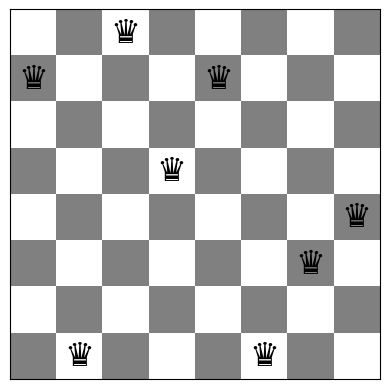

Sau Steepest-ascent HC: [4 6 0 3 1 7 5 2] | h = 0 | số bước = 3 | số lần đánh giá = 169 | kết thúc: solution
Board with 0 conflicts.


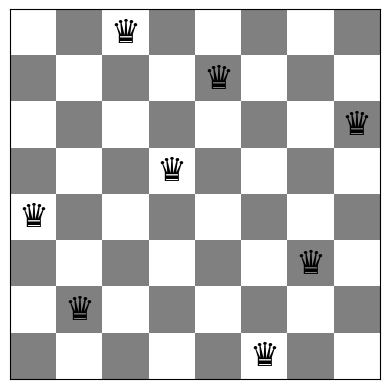

In [7]:
def steepest_ascent_hc(board, max_steps=10_000):
    """Steepest-ascent hill climbing: duyệt mọi láng giềng, chọn nước giảm h nhiều nhất."""
    board = np.array(board).copy()
    n = len(board)
    h_cur = conflicts(board)
    evals, steps, iters = 1, 0, 0
    history, moves_h = [h_cur], [h_cur]
    while h_cur > 0 and steps < max_steps:
        iters += 1
        best_h, best_moves = h_cur, []
        for col in range(n):                      # thử đổi hàng của quân ở cột col
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row
                h_new = conflicts(board); evals += 1
                if h_new < best_h:                # tốt hơn mọi láng giềng đã xét
                    best_h, best_moves = h_new, [(col, row)]
                elif h_new == best_h and best_h < h_cur:   # hòa với nước tốt nhất (và có cải thiện)
                    best_moves.append((col, row))
            board[col] = old                      # hoàn tác trước khi sang cột khác
        if not best_moves:                        # không có nước cải thiện -> cực trị cục bộ / plateau
            break
        col, row = best_moves[np.random.randint(len(best_moves))]
        board[col] = row
        h_cur = best_h; steps += 1
        history.append(h_cur); moves_h.append(h_cur)
    return dict(board=board, h=h_cur, steps=steps, evals=evals, iters=iters, history=history, moves_h=moves_h)


def stuck_type(board):
    """Phân loại trạng thái kết thúc (chỉ để báo cáo, KHÔNG tính vào số lần đánh giá của thuật toán).
    Dùng mã ASCII để CSV dễ gộp giữa các thành viên:
      'solution'         : h = 0
      'plateau'          : h > 0, không có nước cải thiện nhưng có láng giềng cùng h (nước đi ngang)
      'strict_local_min' : h > 0, mọi láng giềng đều có h lớn hơn
      'improvable'       : vẫn còn nước cải thiện (chỉ xảy ra khi thuật toán dừng nhầm)."""
    b = np.array(board).copy(); h0 = conflicts(b)
    if h0 == 0:
        return 'solution'
    equal = False
    for col in range(len(b)):
        old = b[col]
        for row in range(len(b)):
            if row == old:
                continue
            b[col] = row; hn = conflicts(b)
            if hn < h0:
                return 'improvable'
            equal = equal or (hn == h0)
        b[col] = old
    return 'plateau' if equal else 'strict_local_min'


def demo(algo, n=8, k=5, seed=0, **kw):
    """Chạy thuật toán trên k bàn cờ ngẫu nhiên và tóm tắt kết quả."""
    np.random.seed(seed); rows = []
    for i in range(k):
        b0 = random_board(n); r = algo(b0, **kw)
        rows.append({'lượt': i + 1, 'h đầu': conflicts(b0), 'h cuối': r['h'], 'số bước': r['steps'],
                     'số lần đánh giá': r['evals'], 'kết thúc': stuck_type(r['board'])})
    return pd.DataFrame(rows)

def save_board(board, path, fontsize=24):
    """Vẽ bàn cờ giống show_board nhưng lưu thành file ảnh PNG."""
    n = len(board)
    fig, ax = plt.subplots()
    ax.imshow(np.fromfunction(lambda i, j: (i + j) % 2, (n, n)), cmap=colors.ListedColormap(['white', 'gray']))
    ax.set_xticks([]); ax.set_yticks([])
    for j in range(n):
        ax.text(j, board[j], u"\u265B", fontsize=fontsize, ha='center', va='center')
    ax.set_title(f"n = {n}, h = {conflicts(board)}")
    fig.savefig(path, dpi=150, bbox_inches='tight'); plt.close(fig)

# Ví dụ trực quan: một lượt chạy trên n = 8
np.random.seed(11)
b0 = random_board(8)
r = steepest_ascent_hc(b0)
print("Bàn cờ ban đầu:", b0, "| h =", conflicts(b0))
show_board(b0, fontsize=24)
print("Sau Steepest-ascent HC:", r['board'], "| h =", r['h'], "| số bước =", r['steps'],
      "| số lần đánh giá =", r['evals'], "| kết thúc:", stuck_type(r['board']))
show_board(r['board'], fontsize=24)
save_board(b0, 'board_n8_before.png'); save_board(r['board'], 'board_n8_after_steepest.png')   # ảnh bàn cờ để bàn giao

### Kết quả trên 5 bàn cờ ngẫu nhiên (n = 8)

In [8]:
demo(steepest_ascent_hc, n=8, k=5, seed=1)

,lượt,h đầu,h cuối,số bước,số lần đánh giá,kết thúc
0,1,5,0,4,225,solution
1,2,7,2,2,169,plateau
2,3,7,2,3,225,plateau
3,4,8,2,2,169,plateau
4,5,8,2,3,225,plateau


**Nhận xét.** Steepest-ascent HC luôn tiến đều (mỗi bước giảm $h$ chặt) và dừng ngay khi không còn nước cải thiện. Vì chỉ chấp nhận nước đi *chặt*, nó dừng cả ở cực tiểu cục bộ chặt lẫn ở plateau; cột "kết thúc" cho biết từng lượt kết thúc ở dạng nào (`solution`, `plateau` hoặc `strict_local_min`; định nghĩa trong docstring của `stuck_type`). Mỗi vòng lặp tốn đúng $n(n-1)=56$ lần đánh giá với $n=8$, nên số lần đánh giá $=1+56\times(\text{số vòng lặp})$ (ví dụ 169 = 1 + 3×56). Phần lớn lượt kết thúc ở dạng `plateau`: có láng giềng *bằng* $h$ hiện tại nhưng không có láng giềng *tốt hơn*; vì thuật toán không chấp nhận nước đi ngang nên nó dừng ở đó.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

### Cài đặt

**Ý tưởng.** Một *nước đi cục bộ* là chuyển một quân hậu sang hàng khác trong cùng cột, nên mỗi trạng thái có $n(n-1)$ láng giềng. Ở mỗi vòng lặp thuật toán:

1. Tính $h$ của **toàn bộ** $n(n-1)$ láng giềng (mỗi lần gọi `conflicts` tốn $O(n)$).
2. Chọn láng giềng có $h$ nhỏ nhất; nếu có nhiều láng giềng cùng giá trị tốt nhất thì chọn ngẫu nhiên một trong số đó (phá hòa ngẫu nhiên, tránh thiên lệch theo thứ tự duyệt).
3. Chỉ di chuyển nếu $h_{\text{mới}} < h_{\text{hiện tại}}$ (cải thiện **chặt**). Nếu không có láng giềng nào tốt hơn thì dừng: đã đến cực trị cục bộ (hoặc plateau, vì nước đi ngang bằng $h$ không được chấp nhận).

Điều kiện dừng: $h=0$, hoặc không còn nước cải thiện. `max_steps` chỉ là chốt an toàn.

Mỗi thuật toán trả về một dict gồm: bàn cờ cuối, `h` cuối, `steps` (số nước đi đã thực hiện), `evals` (số lần gọi hàm mục tiêu, tính cả lần tính $h$ ban đầu), `iters` (số vòng lặp), `history` (giá trị $h$ sau mỗi vòng lặp) và `moves_h` (giá trị $h$ sau mỗi nước đi được chấp nhận).

In [9]:
def inefficient_stochastic_hc(board, max_steps=10_000):
    """Inefficient stochastic hill climbing: tính mọi láng giềng, chọn ngẫu nhiên một nước CẢI THIỆN."""
    board = np.array(board).copy()
    n = len(board)
    h_cur = conflicts(board)
    evals, steps, iters = 1, 0, 0
    history, moves_h = [h_cur], [h_cur]
    while h_cur > 0 and steps < max_steps:
        iters += 1
        better = []                               # (cột, hàng, h mới) của mọi nước cải thiện
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old:
                    continue
                board[col] = row
                h_new = conflicts(board); evals += 1
                if h_new < h_cur:
                    better.append((col, row, h_new))
            board[col] = old
        if not better:                            # không còn nước cải thiện -> dừng
            break
        col, row, h_new = better[np.random.randint(len(better))]
        board[col] = row
        h_cur = h_new; steps += 1
        history.append(h_cur); moves_h.append(h_cur)
    return dict(board=board, h=h_cur, steps=steps, evals=evals, iters=iters, history=history, moves_h=moves_h)

demo(inefficient_stochastic_hc, n=8, k=5, seed=1)

,lượt,h đầu,h cuối,số bước,số lần đánh giá,kết thúc
0,1,5,1,4,281,plateau
1,2,6,1,3,225,plateau
2,3,9,1,6,393,plateau
3,4,6,1,5,337,strict_local_min
4,5,8,1,3,225,plateau


**Nhận xét.** Vì chọn ngẫu nhiên trong các nước cải thiện nên thuật toán thường cần *nhiều bước hơn* Steepest (mỗi bước có thể giảm $h$ ít hơn mức tối đa), nhưng nhờ tính ngẫu nhiên nó đi theo nhiều quỹ đạo khác nhau từ cùng một trạng thái đầu. Chi phí mỗi vòng vẫn là $n(n-1)$ lần đánh giá, tức là mỗi bước đi đắt như Steepest nhưng ít "tham lam" hơn.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Cài đặt và chọn điều kiện dừng

**Ý tưởng.** Mỗi vòng lặp chỉ sinh **một** láng giềng ngẫu nhiên (chọn ngẫu nhiên một cột và một hàng khác hàng hiện tại, tức lấy mẫu đều trong $N=n(n-1)$ láng giềng), tính $h$ của nó và chấp nhận nếu $h_{\text{mới}}<h_{\text{hiện tại}}$.

**Điều kiện dừng.** Ta không bao giờ duyệt hết láng giềng nên không thể *chắc chắn* đã ở cực trị cục bộ. Ta dừng khi $h=0$ hoặc khi **`patience` lần thử liên tiếp đều không cải thiện**. Chọn `patience` như sau: giả sử trạng thái hiện tại còn ít nhất một nước cải thiện. Mỗi lần lấy mẫu (có hoàn lại) trúng nó với xác suất tối thiểu $1/N$, nên xác suất bỏ sót nước đó sau $x$ lần thử liên tiếp là

$$\left(1-\tfrac1N\right)^{x}\;\approx\; e^{-x/N}.$$

Muốn xác suất kết luận sai (dừng dù vẫn còn nước cải thiện) không quá $\varepsilon=1\%$ thì cần $x \ge N\ln(1/\varepsilon)=N\ln 100\approx 4{,}6\,N$, nên đặt

$$x \;=\; \lceil N \ln 100\rceil, \qquad N=n(n-1).$$

Giá trị này tăng theo $n^2$ (đúng với việc số láng giềng tăng theo $n^2$). Nếu còn nhiều nước cải thiện thì xác suất bỏ sót còn nhỏ hơn nữa. Thêm `max_iters` làm chốt an toàn chống lặp vô hạn.

In [10]:
def default_patience(n, eps=0.01):
    """Số lần thử liên tiếp không cải thiện trước khi dừng: x = ceil(N * ln(1/eps)), N = n(n-1)."""
    return math.ceil(n * (n - 1) * math.log(1 / eps))


def efficient_stochastic_hc(board, patience=None, max_iters=200_000):
    """Efficient stochastic (first-choice) hill climbing: mỗi vòng chỉ sinh MỘT láng giềng ngẫu nhiên."""
    board = np.array(board).copy()
    n = len(board)
    if patience is None:
        patience = default_patience(n)
    h_cur = conflicts(board)
    evals, steps, iters, fails = 1, 0, 0, 0
    history, moves_h = [h_cur], [h_cur]
    while h_cur > 0 and fails < patience and iters < max_iters:
        iters += 1
        col = np.random.randint(n)
        row = np.random.randint(n - 1)            # chọn hàng khác hàng hiện tại, xác suất đều
        if row >= board[col]:
            row += 1
        old = board[col]
        board[col] = row
        h_new = conflicts(board); evals += 1
        if h_new < h_cur:                         # chấp nhận khi cải thiện chặt
            h_cur = h_new; steps += 1; fails = 0
            moves_h.append(h_cur)
        else:                                     # từ chối: hoàn tác
            board[col] = old; fails += 1
        history.append(h_cur)
    return dict(board=board, h=h_cur, steps=steps, evals=evals, iters=iters, history=history, moves_h=moves_h)


def has_improving_move(board):
    """Kiểm tra (ngoài thuật toán, không tính chi phí) xem còn nước cải thiện nào không."""
    return stuck_type(board) == 'improvable'

print("patience theo n:", {n: default_patience(n) for n in (4, 8, 12, 16, 20)})
demo(efficient_stochastic_hc, n=8, k=5, seed=1)

patience theo n: {4: 56, 8: 258, 12: 608, 16: 1106, 20: 1750}


,lượt,h đầu,h cuối,số bước,số lần đánh giá,kết thúc
0,1,5,0,5,73,solution
1,2,7,1,6,309,plateau
2,3,10,2,5,362,plateau
3,4,9,2,5,290,plateau
4,5,7,0,6,98,solution


### Kiểm tra điều kiện dừng có đáng tin không

Với 300 lượt chạy ở $n=8$, ta đếm số lượt thuật toán dừng với $h>0$ **trong khi thực tế vẫn còn nước cải thiện** (dừng nhầm), và so sánh với cách chọn `patience` nhỏ hơn.

In [11]:
def ti_le_dung_nham(n, patience, runs=300, seed=3):
    np.random.seed(seed); nham = ket = 0
    for _ in range(runs):
        r = efficient_stochastic_hc(random_board(n), patience=patience)
        if r['h'] > 0:
            ket += 1; nham += has_improving_move(r['board'])
    return ket, nham

rows = []
for pat in (5, 20, default_patience(8)):
    ket, nham = ti_le_dung_nham(8, pat)
    rows.append({'n': 8, 'patience': pat, 'số lượt dừng với h > 0': ket, 'trong đó dừng nhầm (còn nước cải thiện)': nham})
pd.DataFrame(rows)

,n,patience,số lượt dừng với h > 0,trong đó dừng nhầm (còn nước cải thiện)
0,8,5,299,284
1,8,20,296,186
2,8,258,243,2


**Nhận xét.** Với `patience` = 5 hoặc 20, gần như mọi lượt dừng với $h>0$ đều là dừng nhầm (284/299 và 186/296 lượt: còn nước cải thiện mà thuật toán đã bỏ cuộc). Với $x=\lceil N\ln100\rceil=258$ chỉ còn 2/243 lượt dừng nhầm (khoảng 0,8%), khớp với ngưỡng $\varepsilon=1\%$ đã chọn. Cái giá phải trả là $x$ lần đánh giá "tốn thêm" ở cuối mỗi lượt chạy bị kẹt, nên với bàn cờ nhỏ tổng số lần đánh giá của bản "efficient" chưa chắc thấp hơn các bản còn lại (xem câu hỏi thảo luận 5). Lợi thế thực sự của nó là chi phí *mỗi lần thử* chỉ là 1 lần đánh giá thay vì $n(n-1)$.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

### Cài đặt và thí nghiệm

**Random Restart.** Chạy một thuật toán hill climbing từ một bàn cờ ngẫu nhiên; nếu kết thúc với $h>0$ thì sinh bàn cờ ngẫu nhiên mới và chạy lại, cho đến khi $h=0$ hoặc đã dùng hết **tối đa 100 lần khởi tạo** (1 lần chạy đầu + tối đa 99 lần khởi động lại; mình đếm 100 là tổng số lần chạy). Thuật toán trả về bàn cờ tốt nhất ($h$ nhỏ nhất) trong các lần chạy. Chi phí tổng = tổng số lần đánh giá và tổng thời gian của mọi lần chạy.

**Thí nghiệm.** Mỗi biến thể (Steepest, Inefficient Stochastic, Efficient Stochastic) được bọc Random Restart rồi chạy **100 lượt độc lập** ở $n=4$ và $n=8$; ta thống kê số lượt thành công ($h=0$ trong giới hạn 100 lần khởi tạo), số lần khởi tạo trung bình và chi phí tính toán. Seed cố định để kết quả tái lập được.

In [12]:
MEMBER = 'TV2'
ALGOS = {'Steepest HC': steepest_ascent_hc,
         'Inefficient Stochastic HC': inefficient_stochastic_hc,
         'Efficient Stochastic HC': efficient_stochastic_hc}
MAX_STARTS = 100          # tối đa 100 lần khởi tạo cho mỗi lượt Random Restart
N_RR_TRIALS = 100         # số lượt Random Restart độc lập cho mỗi (thuật toán, n)


def random_restart(algo, n, max_starts=MAX_STARTS):
    """Chạy lại `algo` từ bàn cờ ngẫu nhiên mới cho tới khi h = 0 hoặc hết max_starts lần."""
    t0 = time.perf_counter()
    evals = steps = starts = 0
    best_h, best_board = None, None
    for _ in range(max_starts):
        r = algo(random_board(n))
        starts += 1; evals += r['evals']; steps += r['steps']
        if best_h is None or r['h'] < best_h:
            best_h, best_board = r['h'], r['board']
        if r['h'] == 0:
            break
    return dict(board=best_board, h=best_h, success=(best_h == 0), starts=starts,
                evals=evals, steps=steps, time=time.perf_counter() - t0)


def run_rr_experiment(n, trials=N_RR_TRIALS, seed=4000):
    rows = []
    for name, algo in ALGOS.items():
        np.random.seed(seed + n)                  # cùng seed cho mỗi thuật toán
        for i in range(trials):
            r = random_restart(algo, n)
            rows.append(dict(member=MEMBER, task='Task 4', algorithm=f'Random Restart ({name})', n=n, run_id=i + 1,
                             success=int(r['success']), final_h=r['h'], steps=r['steps'], evals=r['evals'],
                             time_s=r['time'], restarts=r['starts'], end_type=stuck_type(r['board'])))
    return rows


rr_rows = run_rr_experiment(4) + run_rr_experiment(8)
df_rr = pd.DataFrame(rr_rows)
rr_summary = (df_rr.groupby(['n', 'algorithm'], sort=False)
              .agg(lượt=('run_id', 'count'), thành_công_pct=('success', lambda s: 100 * s.mean()),
                   số_lần_khởi_tạo_TB=('restarts', 'mean'), số_lần_khởi_tạo_max=('restarts', 'max'), số_lần_đánh_giá_TB=('evals', 'mean'),
                   thời_gian_TB_s=('time_s', 'mean'))
              .round({'thành_công_pct': 1, 'số_lần_khởi_tạo_TB': 2, 'số_lần_đánh_giá_TB': 0, 'thời_gian_TB_s': 4}))
rr_summary

lượt  thành_công_pct  số_lần_khởi_tạo_TB  số_lần_khởi_tạo_max  số_lần_đánh_giá_TB  thời_gian_TB_s
n algorithm                                                                                                                                    
4 Random Restart (Steepest HC)                 100           100.0                2.45                   13                66.0          0.0011
  Random Restart (Inefficient Stochastic HC)   100           100.0                3.08                   15                98.0          0.0016
  Random Restart (Efficient Stochastic HC)     100           100.0                2.99                   11               144.0          0.0040
8 Random Restart (Steepest HC)                 100           100.0                8.11                   42              1865.0          0.0360
  Random Restart (Inefficient Stochastic HC)   100           100.0                7.35                   35              2432.0          0.0347
  Random Restart (Efficient Stochastic HC)     100           100.0                6.23                   25              1791.0          0.0370

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [13]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

**Thiết lập thí nghiệm.**

* $n\in\{4,8\}$; mỗi thuật toán chạy **200 lượt** (≥ 100 theo yêu cầu) trên **cùng 200 bàn cờ khởi tạo** (sinh bằng seed cố định), nên ba biến thể hill climbing được so sánh trên đúng cùng dữ liệu đầu vào. Các lựa chọn ngẫu nhiên bên trong thuật toán dùng seed cố định riêng.
* Random Restart: 100 lượt độc lập mỗi (biến thể, $n$), mỗi lượt tối đa 100 lần khởi tạo (kết quả từ Task 4).
* Số liệu ghi cho mỗi lượt: thành công ($h=0$), $h$ cuối, số bước, số lần đánh giá hàm mục tiêu, thời gian (`time.perf_counter()`), số lần khởi tạo, và dạng kết thúc (nghiệm / plateau / cực tiểu cục bộ chặt).
* Thành công = $h=0$ sau khi thuật toán tự dừng; "xung đột cuối TB" là trung bình $h$ cuối (với Random Restart là $h$ của bàn cờ tốt nhất).
* Thời gian đo trên máy chạy notebook nên tùy phần cứng; so sánh *tương đối* giữa các thuật toán mới là điều có ý nghĩa.

In [14]:
N_RUNS = 200               # số lượt cho mỗi (thuật toán, n) ở chế độ chạy một lần
SEED_BASE = 6000
hist_store = {}            # moves_h của các lượt n = 8, dùng để vẽ đường hội tụ trung bình

def run_single_experiment(n, runs=N_RUNS, seed=SEED_BASE):
    np.random.seed(seed + n)
    starts = [random_board(n) for _ in range(runs)]         # cùng bàn cờ khởi tạo cho mọi thuật toán
    rows = []
    for name, algo in ALGOS.items():
        np.random.seed(seed + 100 + n)                       # seed cho các lựa chọn ngẫu nhiên bên trong thuật toán
        for i, b0 in enumerate(starts):
            t0 = time.perf_counter()
            r = algo(b0)
            dt = time.perf_counter() - t0
            rows.append(dict(member=MEMBER, task='Task 6', algorithm=name, n=n, run_id=i + 1,
                             success=int(r['h'] == 0), final_h=r['h'], steps=r['steps'], evals=r['evals'],
                             time_s=dt, restarts=1, end_type=stuck_type(r['board'])))
            if n == 8:
                hist_store.setdefault(name, []).append(r['moves_h'])
    return rows

df_single = pd.DataFrame(run_single_experiment(4) + run_single_experiment(8))
df_all = pd.concat([df_single, df_rr], ignore_index=True)

def summarize(df):
    g = (df.groupby(['n', 'algorithm'], sort=False)
         .agg(lượt=('run_id', 'count'), thành_công_pct=('success', lambda s: 100 * s.mean()),
              xung_đột_cuối_TB=('final_h', 'mean'), số_bước_TB=('steps', 'mean'),
              số_lần_đánh_giá_TB=('evals', 'mean'), thời_gian_TB_s=('time_s', 'mean'),
              số_lần_khởi_tạo_TB=('restarts', 'mean')))
    return g.round({'thành_công_pct': 1, 'xung_đột_cuối_TB': 3, 'số_bước_TB': 2, 'số_lần_đánh_giá_TB': 1,
                    'thời_gian_TB_s': 5, 'số_lần_khởi_tạo_TB': 2})

summary = summarize(df_all)
summary

lượt  thành_công_pct  xung_đột_cuối_TB  số_bước_TB  số_lần_đánh_giá_TB  thời_gian_TB_s  số_lần_khởi_tạo_TB
n algorithm                                                                                                                                             
4 Steepest HC                                  200            34.5             0.730        1.49                26.7         0.00020                1.00
  Inefficient Stochastic HC                    200            29.0             0.835        1.78                30.9         0.00022                1.00
  Efficient Stochastic HC                      200            31.5             0.845        1.84                49.7         0.00067                1.00
8 Steepest HC                                  200            16.0             1.200        3.21               227.8         0.00359                1.00
  Inefficient Stochastic HC                    200            15.0             1.305        4.84               319.6         0.00772                1.00
  Efficient Stochastic HC                      200            14.5             1.350        4.84               286.4         0.01023                1.00
4 Random Restart (Steepest HC)                 100           100.0             0.000        3.87                66.3         0.00110                2.45
  Random Restart (Inefficient Stochastic HC)   100           100.0             0.000        5.83                98.0         0.00164                3.08
  Random Restart (Efficient Stochastic HC)     100           100.0             0.000        5.62               143.8         0.00403                2.99
8 Random Restart (Steepest HC)                 100           100.0             0.000       26.05              1865.1         0.03602                8.11
  Random Restart (Inefficient Stochastic HC)   100           100.0             0.000       36.94              2431.6         0.03472                7.35
  Random Restart (Efficient Stochastic HC)     100           100.0             0.000       31.40              1790.7         0.03704                6.23

### Bảng so sánh 

Các dòng *Simulated Annealing* thuộc phần của thành viên khác nên để trống ở đây.

In [15]:
s1 = df_single.groupby(['algorithm', 'n'], sort=False).agg(
    tb_time=('time_s', 'mean'), tb_conf=('final_h', 'mean'), opt=('success', lambda s: 100 * s.mean())).reset_index()
tmpl = []
for n in (4, 8):
    for name in ALGOS:
        r = s1[(s1.algorithm == name) & (s1.n == n)].iloc[0]
        tmpl.append({'Algorithm': name, 'Board size': n, 'Avg. run time (s)': round(r.tb_time, 5),
                     'Avg. number of conflicts': round(r.tb_conf, 3), '% of runs ending in optimal solution': round(r.opt, 1)})
    tmpl.append({'Algorithm': 'Simulated Annealing', 'Board size': n, 'Avg. run time (s)': '(TV khác)',
                 'Avg. number of conflicts': '(TV khác)', '% of runs ending in optimal solution': '(TV khác)'})
pd.DataFrame(tmpl)

,Algorithm,Board size,Avg. run time (s),Avg. number of conflicts,% of runs ending in optimal solution
0,Steepest HC,4,0.0002,0.73,34.5
1,Inefficient Stochastic HC,4,0.00022,0.835,29.0
2,Efficient Stochastic HC,4,0.00067,0.845,31.5
3,Simulated Annealing,4,(TV khác),(TV khác),(TV khác)
4,Steepest HC,8,0.00359,1.2,16.0
5,Inefficient Stochastic HC,8,0.00772,1.305,15.0
6,Efficient Stochastic HC,8,0.01023,1.35,14.5
7,Simulated Annealing,8,(TV khác),(TV khác),(TV khác)


**Nhận xét.**

* **Một lần chạy hill climbing (không restart).** Tỷ lệ thành công thấp: khoảng 29–35% ở $n=4$ và khoảng 14,5–16% ở $n=8$; xung đột cuối trung bình vẫn nhỏ (0,7–0,85 ở $n=4$, 1,2–1,35 ở $n=8$), tức là thuật toán thường dừng *rất gần* nghiệm nhưng chưa tới. Với 200 lượt, sai số chuẩn của tỷ lệ thành công khoảng 2,5 điểm phần trăm ở $n=8$, nên chênh lệch giữa ba biến thể (16,0% / 15,0% / 14,5%) **không đủ cơ sở để xếp hạng chất lượng**.
* **Chi phí.** Steepest dùng ít bước nhất (3,2 so với 4,8 bước ở $n=8$) và ít lần đánh giá nhất. Về thời gian, trên máy mình thứ tự là Steepest < Inefficient < Efficient dù số lần đánh giá của Efficient ít hơn Inefficient; lý do là mỗi vòng lặp của Efficient trong Python tốn thêm việc sinh số ngẫu nhiên và hoàn tác, tức là thời gian phụ thuộc cài đặt chứ không chỉ số lần đánh giá.
* **Random Restart** đưa tỷ lệ thành công lên 100% ở cả hai kích thước (xem bảng Task 4 và Bảng 4.2) với giá là gấp khoảng 6–8 lần chi phí của một lần chạy ở $n=8$.

### Xuất CSV theo định dạng chung

Mỗi dòng là một lượt chạy. Danh sách cột nằm trong `COLUMNS` để dễ đổi tên/thứ tự cột cho khớp định dạng chung của nhóm (nếu nhóm quy định khác). Các file được ghi cạnh notebook (đường dẫn tương đối, không phụ thuộc máy cá nhân). Chạy notebook từ đầu đến cuối là tạo ra đủ:

* `results_hc.csv`: kết quả từng lượt (n = 4 và 8; ba biến thể HC + Random Restart);
* `summary_hc.csv`: bảng tổng hợp theo (thuật toán, n);
* `history_hc.csv` (lịch sử $h$ theo vòng lặp của lượt đại diện, n = 8), `timing_hc.csv` (thời gian theo $n$) và `bang_4_2_hc.csv` được xuất ở các mục bên dưới; ảnh bàn cờ được lưu thành `board_n8_before.png` và `board_n8_after_steepest.png` ở Task 1. Cột `end_type` dùng mã ASCII: `solution`, `plateau`, `strict_local_min`.

In [16]:
OUT_DIR = '.'          # ghi file cạnh notebook
os.makedirs(OUT_DIR, exist_ok=True)

COLUMNS = ['member', 'task', 'algorithm', 'n', 'run_id', 'success', 'final_h', 'steps', 'evals', 'time_s', 'restarts', 'end_type']
df_all[COLUMNS].to_csv(os.path.join(OUT_DIR, 'results_hc.csv'), index=False, float_format='%.6f')
summary.reset_index().to_csv(os.path.join(OUT_DIR, 'summary_hc.csv'), index=False)
print("Đã ghi:", sorted(f for f in os.listdir(OUT_DIR) if f.endswith('.csv')))
df_all[COLUMNS].head()

Đã ghi: ['results_hc.csv', 'summary_hc.csv']


,member,task,algorithm,n,run_id,success,final_h,steps,evals,time_s,restarts,end_type
0,TV2,Task 6,Steepest HC,4,1,0,1,0,13,0.000201,1,plateau
1,TV2,Task 6,Steepest HC,4,2,1,0,2,25,0.000254,1,solution
2,TV2,Task 6,Steepest HC,4,3,1,0,2,25,0.000190,1,solution
3,TV2,Task 6,Steepest HC,4,4,1,0,0,1,0.000010,1,solution
4,TV2,Task 6,Steepest HC,4,5,0,1,1,25,0.000179,1,plateau


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

### Đường hội tụ của $h$ (n = 8)

**Hình 1** vẽ $h$ theo số vòng lặp cho **một lượt đại diện** của mỗi thuật toán; cả ba cùng xuất phát từ một bàn cờ ($n=8$, $h$ đầu $\ge 8$). Vì khoảng 85% lượt chạy của cả ba thuật toán bị kẹt (xem Hình 2b), mình chọn bàn cờ đầu tiên (theo seed tăng dần) mà **cả ba thuật toán đều kết thúc với $h>0$**, tức là minh họa trường hợp điển hình chứ không phải trường hợp may mắn. Một "vòng lặp" của Steepest/Inefficient là một lần quét toàn bộ láng giềng (kèm một nước đi); của Efficient là một lần thử một láng giềng ngẫu nhiên, nên đường cong của nó dài hơn nhiều và có những đoạn nằm ngang (các lần thử bị từ chối, gồm cả `patience` lần cuối).

**Hình 2** cho cái nhìn tổng quát hơn: (trái) $h$ trung bình theo *số nước đi được chấp nhận* trên 200 lượt, (phải) tỷ lệ các dạng kết thúc ở $n=8$.

Bàn cờ xuất phát của lượt đại diện (seed = 6 ): [2 1 3 4 2 5 7 2] | h = 8


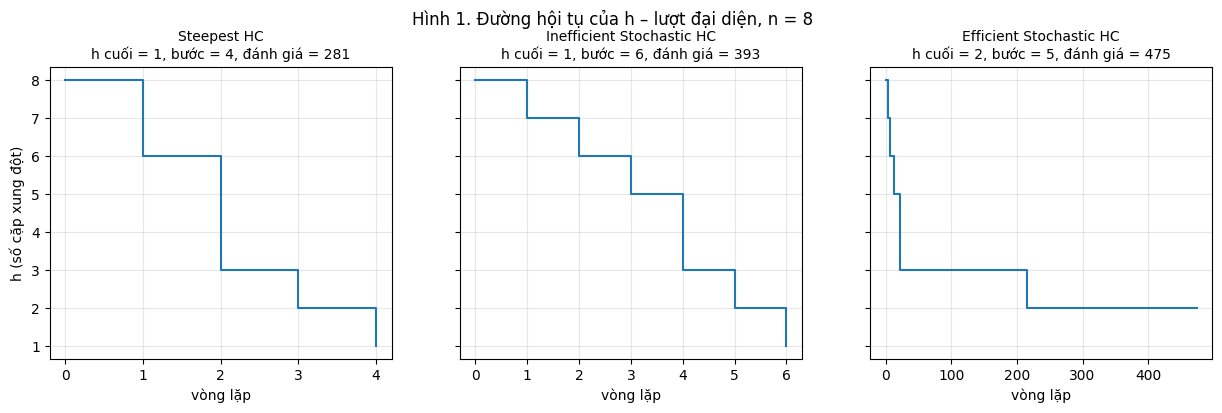

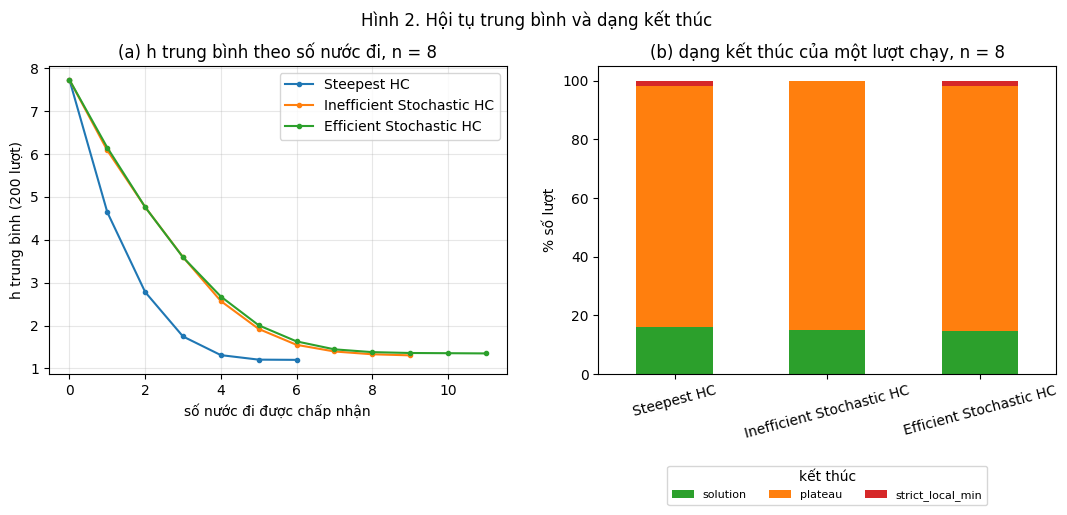

end_type,solution,plateau,strict_local_min
algorithm,,,
Steepest HC,16.0,82.0,2.0
Inefficient Stochastic HC,15.0,85.0,0.0
Efficient Stochastic HC,14.5,83.5,2.0


In [17]:
# Chọn lượt đại diện: bàn cờ n = 8 có h đầu >= 8 mà cả ba thuật toán đều kết thúc với h > 0 (trường hợp điển hình)
for s in range(1000):
    np.random.seed(s)
    b_rep = random_board(8)
    if conflicts(b_rep) < 8:
        continue
    rep = {}
    for name, algo in ALGOS.items():
        np.random.seed(77)
        rep[name] = algo(b_rep)
    if all(r['h'] > 0 for r in rep.values()):
        break
print("Bàn cờ xuất phát của lượt đại diện (seed =", s, "):", b_rep, "| h =", conflicts(b_rep))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (name, r) in zip(axes, rep.items()):
    ax.step(range(len(r['history'])), r['history'], where='post')
    ax.set_title(f"{name}\nh cuối = {r['h']}, bước = {r['steps']}, đánh giá = {r['evals']}", fontsize=10)
    ax.set_xlabel('vòng lặp'); ax.grid(alpha=.3)
axes[0].set_ylabel('h (số cặp xung đột)')
fig.suptitle('Hình 1. Đường hội tụ của h – lượt đại diện, n = 8', y=1.03)
plt.show()

# CSV lịch sử h của lượt đại diện
hist_rows = [dict(member=MEMBER, algorithm=name, n=8, run_id='representative', iteration=i, h=hv)
             for name, r in rep.items() for i, hv in enumerate(r['history'])]
pd.DataFrame(hist_rows).to_csv(os.path.join(OUT_DIR, 'history_hc.csv'), index=False)

# Hình 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, lst in hist_store.items():
    L = max(len(x) for x in lst)
    M = np.array([x + [x[-1]] * (L - len(x)) for x in lst])        # kéo dài bằng giá trị cuối (đã dừng)
    ax1.plot(M.mean(axis=0), marker='o', ms=3, label=name)
ax1.set_xlabel('số nước đi được chấp nhận'); ax1.set_ylabel('h trung bình (200 lượt)')
ax1.set_title('(a) h trung bình theo số nước đi, n = 8'); ax1.grid(alpha=.3); ax1.legend()

d8 = df_single[df_single.n == 8]
ct = pd.crosstab(d8.algorithm, d8.end_type, normalize='index').reindex(list(ALGOS)) * 100
ct = ct.reindex(columns=['solution', 'plateau', 'strict_local_min']).fillna(0)
ct.plot(kind='bar', stacked=True, ax=ax2, rot=15, color=['#2ca02c', '#ff7f0e', '#d62728'])
ax2.set_ylabel('% số lượt'); ax2.set_xlabel('')
ax2.set_title('(b) dạng kết thúc của một lượt chạy, n = 8')
ax2.legend(title='kết thúc', fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=3)
fig.suptitle('Hình 2. Hội tụ trung bình và dạng kết thúc', y=1.02)
plt.show()
(ct.round(1))

**Nhận xét về hội tụ (n = 8).**

* **Mẫu hội tụ điển hình.** Cả ba thuật toán cải thiện *rất nhanh ở những nước đi đầu* rồi phẳng ra. Hình 2a: $h$ trung bình giảm từ khoảng 7,7 xuống khoảng 4,6 chỉ sau nước đi thứ nhất của Steepest và xuống khoảng 2,8 sau nước thứ hai, rồi tiến sát khoảng 1,2. Steepest giảm nhanh hơn theo *số nước đi* vì mỗi bước đều chọn mức giảm lớn nhất. Hai biến thể stochastic có đường trung bình gần như trùng nhau (cả hai chọn đều trong các nước cải thiện), chậm hơn Steepest và dừng ở mức cao hơn một chút (khoảng 1,3–1,35).
* **Plateau / kẹt.** Hình 2b: khoảng 84–85,5% lượt chạy của cả ba thuật toán kết thúc với $h>0$, hầu như toàn bộ ở dạng `plateau` (có láng giềng bằng $h$ nhưng không có láng giềng tốt hơn); cực tiểu cục bộ chặt chỉ chiếm 0–2%. Trong các lượt thất bại ở $n=8$ của Steepest, $h$ cuối là 1 (104 lượt), 2 (57 lượt), 3 (6 lượt) hoặc 4 (1 lượt). Ba thuật toán có tỷ lệ kẹt tương đương nhau (chênh lệch nhỏ hơn sai số lấy mẫu), nên mình không kết luận thuật toán nào kẹt thường xuyên hơn.
* **Riêng Efficient Stochastic** có đoạn nằm ngang dài ở cuối đường cong (Hình 1): đó là `patience` lần thử bị từ chối trước khi thuật toán tuyên bố dừng. Đoạn này không cải thiện $h$ nhưng vẫn tốn đủ số lần đánh giá.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

### Thí nghiệm

Đo thời gian chạy theo $n\in\{4,8,12,16,20\}$. Với mỗi $n$: 30 lượt cho ba biến thể hill climbing (một lần chạy, không restart) và 20 lượt cho hai biến thể có Random Restart (Steepest và Efficient Stochastic, tối đa 100 lần khởi tạo). Thời gian là trung bình trên các lượt (gồm cả lượt thất bại). Sau đó khớp đường thẳng trong thang log-log, $\log t = k\log n + c$, để ước lượng số mũ thực nghiệm $k$ (tức $t\approx C\,n^{k}$).

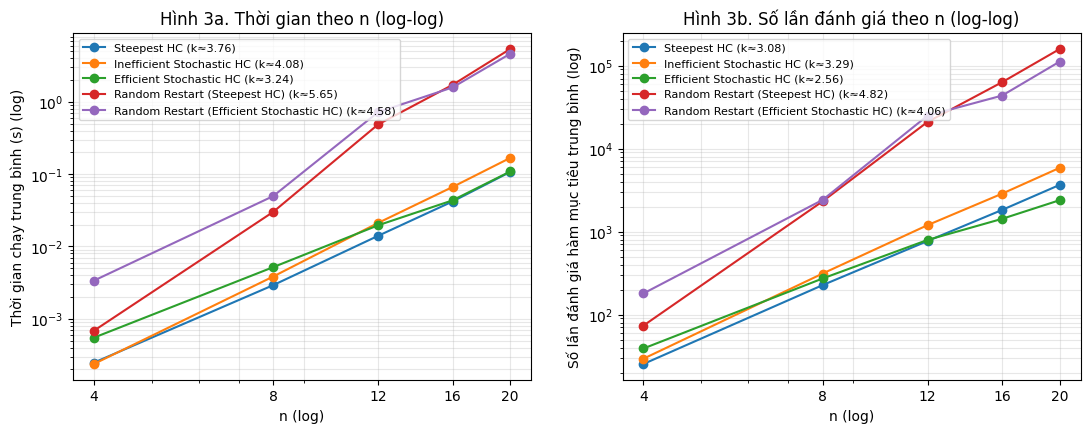

member                                algorithm  n  runs  avg_time_s  avg_evals  success_rate
   TV2                              Steepest HC  4    30     0.00025       25.4          0.50
   TV2                Inefficient Stochastic HC  4    30     0.00024       29.4          0.37
   TV2                  Efficient Stochastic HC  4    30     0.00055       39.0          0.57
   TV2             Random Restart (Steepest HC)  4    20     0.00068       73.7          1.00
   TV2 Random Restart (Efficient Stochastic HC)  4    20     0.00337      179.9          1.00
   TV2                              Steepest HC  8    30     0.00292      226.9          0.23
   TV2                Inefficient Stochastic HC  8    30     0.00384      312.7          0.07
   TV2                  Efficient Stochastic HC  8    30     0.00518      272.7          0.17
   TV2             Random Restart (Steepest HC)  8    20     0.03007     2322.8          1.00
   TV2 Random Restart (Efficient Stochastic HC)  8    20    

,thuật toán,số mũ k (thời gian),số mũ k (số lần đánh giá)
0,Steepest HC,3.76,3.08
1,Inefficient Stochastic HC,4.08,3.29
2,Efficient Stochastic HC,3.24,2.56
3,Random Restart (Steepest HC),5.65,4.82
4,Random Restart (Efficient Stochastic HC),4.58,4.06


In [18]:
NS = [4, 8, 12, 16, 20]
runs_hc, runs_rr = 30, 20
scal_rows = []
for n in NS:
    for name, algo in ALGOS.items():
        np.random.seed(9000 + n)
        ts, ev, ok = [], [], []
        for _ in range(runs_hc):
            b0 = random_board(n); t0 = time.perf_counter(); r = algo(b0); ts.append(time.perf_counter() - t0)
            ev.append(r['evals']); ok.append(r['h'] == 0)
        scal_rows.append(dict(member=MEMBER, algorithm=name, n=n, runs=runs_hc, avg_time_s=np.mean(ts),
                              avg_evals=np.mean(ev), success_rate=np.mean(ok)))
    for name in ('Steepest HC', 'Efficient Stochastic HC'):
        np.random.seed(9500 + n)
        res = [random_restart(ALGOS[name], n) for _ in range(runs_rr)]
        scal_rows.append(dict(member=MEMBER, algorithm=f'Random Restart ({name})', n=n, runs=runs_rr,
                              avg_time_s=np.mean([r['time'] for r in res]), avg_evals=np.mean([r['evals'] for r in res]),
                              success_rate=np.mean([r['success'] for r in res])))
df_scal = pd.DataFrame(scal_rows)
df_scal.to_csv(os.path.join(OUT_DIR, 'timing_hc.csv'), index=False, float_format='%.6f')

# Khớp log-log
fit = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in df_scal.groupby('algorithm', sort=False):
    k_t, c_t = np.polyfit(np.log10(g.n), np.log10(g.avg_time_s), 1)
    k_e, c_e = np.polyfit(np.log10(g.n), np.log10(g.avg_evals), 1)
    fit.append({'thuật toán': name, 'số mũ k (thời gian)': round(k_t, 2), 'số mũ k (số lần đánh giá)': round(k_e, 2)})
    axes[0].loglog(g.n, g.avg_time_s, marker='o', label=f'{name} (k≈{k_t:.2f})')
    axes[1].loglog(g.n, g.avg_evals, marker='o', label=f'{name} (k≈{k_e:.2f})')
for ax, t in zip(axes, ('Thời gian chạy trung bình (s)', 'Số lần đánh giá hàm mục tiêu trung bình')):
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel('n (log)'); ax.set_ylabel(t + ' (log)'); ax.set_xticks(NS); ax.set_xticklabels(NS)
    ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
axes[0].set_title('Hình 3a. Thời gian theo n (log-log)'); axes[1].set_title('Hình 3b. Số lần đánh giá theo n (log-log)')
plt.show()
print(df_scal.round({'avg_time_s': 5, 'avg_evals': 1, 'success_rate': 2}).to_string(index=False))
pd.DataFrame(fit)

**Nhận xét về khả năng mở rộng.** (Số mũ $k$ lấy từ bảng ở trên trong lần chạy của mình; chúng được khớp từ chỉ 5 điểm $n$ và thời gian rất nhỏ ở $n$ bé nên chỉ là ước lượng thô.)

* **Steepest HC: $k\approx3{,}6$ về thời gian**, tức gần $O(n^4)$. Giải thích: mỗi vòng lặp đánh giá $n(n-1)=O(n^2)$ láng giềng, mỗi lần gọi `conflicts` tốn $O(n)$, nên một vòng lặp là $O(n^3)$; nếu số bước tăng xấp xỉ tuyến tính theo $n$ thì cả lượt chạy là $O(n^4)$. Số lần đánh giá riêng có $k\approx3{,}1$ (mỗi lần đánh giá lại tốn thêm một bậc $n$). Inefficient Stochastic cho kết quả tương tự ($k\approx3{,}8$) nhưng hằng số lớn hơn vì cần nhiều bước hơn.
* **Efficient Stochastic HC: $k\approx2{,}9$**, nhỏ nhất trong ba biến thể. Chi phí chủ yếu là đuôi `patience` $\propto n^2$ lần thử, mỗi lần $O(n)$, nên $O(n^3)$; số lần đánh giá có $k\approx2{,}6$ vì ở các $n$ nhỏ này đuôi $\propto n^2$ chiếm gần hết. Từ $n\ge16$ nó cũng là biến thể rẻ nhất về số lần đánh giá và thời gian.
* **Random Restart** nhân thêm *số lần khởi tạo cần thiết*, tăng rất nhanh khi $n$ tăng vì xác suất một lần chạy thành công giảm (ở $n=16$–$20$ một lần chạy gần như luôn thất bại). Số mũ của chúng ($k\approx5{,}3$ cho Steepest và $\approx4{,}6$ cho Efficient) vì vậy cao hơn, và còn bị chặn bởi giới hạn 100 lần khởi tạo: ở $n=20$ một số lượt Random Restart không tìm được nghiệm (xem cột `success_rate`), nên số mũ này chỉ mô tả *thí nghiệm này* chứ không phải độ phức tạp tiệm cận.
* **Kết luận.** Trong các biến thể chạy một lần, Efficient Stochastic mở rộng tốt nhất; khi cần *chắc chắn* tìm được nghiệm ở $n$ lớn thì Random Restart bọc quanh biến thể Efficient tốn ít lần đánh giá hơn Random Restart bọc Steepest ở $n=16$ và $n=20$.
* **Phụ thuộc cài đặt.** `conflicts` tính lại từ đầu ($O(n)$); nếu tính *chênh lệch* $\Delta h$ khi di chuyển một quân ($O(1)$) thì mỗi số mũ ở trên sẽ giảm khoảng 1. Python thuần cũng làm hằng số lớn hơn nhiều so với cài đặt biên dịch.

## Bảng 4.2 

Số liệu lấy từ Task 4 và Task 6 ở trên (200 lượt cho HC chạy một lần, 100 lượt cho Random Restart). *Stochastic HC* ở đây là bản **Efficient** (first-choice); bản Inefficient cũng được liệt kê để đối chiếu. **COUNT** của bài tô màu không đồng nhất với số lần đánh giá hàm mục tiêu ở n-Queens: ở đây cột "số lần đánh giá" đếm số lần gọi `conflicts()`.

In [19]:
def row42(n, algo_name, tieu_chi_dung):
    g = df_all[(df_all.n == n) & (df_all.algorithm == algo_name)]
    return {'Bài toán': 'n-Queens', 'Kích thước': f'n = {n}', 'Thuật toán': algo_name,
            'Số màu / lượt': f'{len(g)} lượt', 'Thành công (%)': round(100 * g.success.mean(), 1),
            'Xung đột cuối TB': round(g.final_h.mean(), 3), 'Số lần đánh giá TB': round(g.evals.mean(), 1),
            'Thời gian TB (s)': round(g.time_s.mean(), 5), 'Tiêu chí dừng': tieu_chi_dung}

stop_hc = 'h = 0 hoặc hết nước cải thiện'
stop_st = 'h = 0 hoặc patience lần thử liên tiếp không cải thiện'
stop_rr = 'h = 0 hoặc đủ 100 lần khởi tạo'
rows = [
    row42(4, 'Steepest HC', stop_hc), row42(8, 'Steepest HC', stop_hc),
    row42(4, 'Efficient Stochastic HC', stop_st), row42(8, 'Efficient Stochastic HC', stop_st),
    row42(8, 'Inefficient Stochastic HC', stop_hc),
    row42(8, 'Random Restart (Steepest HC)', stop_rr),
    row42(8, 'Random Restart (Inefficient Stochastic HC)', stop_rr),
    row42(8, 'Random Restart (Efficient Stochastic HC)', stop_rr),
]
t42 = pd.DataFrame(rows)
t42.to_csv(os.path.join(OUT_DIR, 'bang_4_2_hc.csv'), index=False)
t42

,Bài toán,Kích thước,Thuật toán,Số màu / lượt,Thành công (%),Xung đột cuối TB,Số lần đánh giá TB,Thời gian TB (s),Tiêu chí dừng
0,n-Queens,n = 4,Steepest HC,200 lượt,34.5,0.730,26.7,0.00020,h = 0 hoặc hết nước cải thiện
1,n-Queens,n = 8,Steepest HC,200 lượt,16.0,1.200,227.8,0.00359,h = 0 hoặc hết nước cải thiện
2,n-Queens,n = 4,Efficient Stochastic HC,200 lượt,31.5,0.845,49.7,0.00067,h = 0 hoặc patience lần thử liên tiếp không cả...
3,n-Queens,n = 8,Efficient Stochastic HC,200 lượt,14.5,1.350,286.4,0.01023,h = 0 hoặc patience lần thử liên tiếp không cả...
4,n-Queens,n = 8,Inefficient Stochastic HC,200 lượt,15.0,1.305,319.6,0.00772,h = 0 hoặc hết nước cải thiện
5,n-Queens,n = 8,Random Restart (Steepest HC),100 lượt,100.0,0.000,1865.1,0.03602,h = 0 hoặc đủ 100 lần khởi tạo
6,n-Queens,n = 8,Random Restart (Inefficient Stochastic HC),100 lượt,100.0,0.000,2431.6,0.03472,h = 0 hoặc đủ 100 lần khởi tạo
7,n-Queens,n = 8,Random Restart (Efficient Stochastic HC),100 lượt,100.0,0.000,1790.7,0.03704,h = 0 hoặc đủ 100 lần khởi tạo


### So sánh Steepest, Inefficient Stochastic và Efficient Stochastic về số lần đánh giá láng giềng

Bảng dưới tổng hợp từ 200 lượt mỗi thuật toán (Task 6): số lần đánh giá trung bình, số nước đi được chấp nhận, số lần đánh giá trên mỗi nước đi, và số lần đánh giá *trên mỗi vòng lặp*. Bảng thứ hai tách riêng các lượt thành công và thất bại ở $n=8$.

In [20]:
PER_ITER = lambda n, a: 1 if a == 'Efficient Stochastic HC' else n * (n - 1)
q5 = (df_single.groupby(['n', 'algorithm'], sort=False)
      .agg(số_lần_đánh_giá_TB=('evals', 'mean'), số_nước_đi_TB=('steps', 'mean')))
q5['đánh_giá_mỗi_nước_đi'] = q5['số_lần_đánh_giá_TB'] / q5['số_nước_đi_TB']
q5['đánh_giá_mỗi_vòng_lặp'] = [PER_ITER(n, a) for n, a in q5.index]
display_q5 = q5.round(1)

q5b = (df_single[df_single.n == 8].groupby(['algorithm', 'success']).evals.mean().unstack()
       .rename(columns={0: 'lượt thất bại (kẹt)', 1: 'lượt thành công'}).round(1))
print(display_q5.to_string()); print()
print("Số lần đánh giá TB ở n = 8, tách theo kết quả của lượt chạy (patience của Efficient ở n = 8 là",
      default_patience(8), "):")
q5b

                             số_lần_đánh_giá_TB  số_nước_đi_TB  đánh_giá_mỗi_nước_đi  đánh_giá_mỗi_vòng_lặp
n algorithm                                                                                                
4 Steepest HC                              26.7            1.5                  17.9                     12
  Inefficient Stochastic HC                30.9            1.8                  17.3                     12
  Efficient Stochastic HC                  49.7            1.8                  27.0                      1
8 Steepest HC                             227.8            3.2                  71.0                     56
  Inefficient Stochastic HC               319.6            4.8                  66.0                     56
  Efficient Stochastic HC                 286.4            4.8                  59.2                      1

Số lần đánh giá TB ở n = 8, tách theo kết quả của lượt chạy (patience của Efficient ở n = 8 là 258 ):


success,lượt thất bại (kẹt),lượt thành công
algorithm,,
Efficient Stochastic HC,317.6,102.5
Inefficient Stochastic HC,314.3,350.1
Steepest HC,226.7,233.8


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [21]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [22]:
# Code and description go here